In [ ]:
!pip install opencv-python ultralytics easyocr numpy


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 24.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 78.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 15.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 48.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.7/295.7 kB 21.1 MB/s eta 0:00:00


In [ ]:
import cv2
import easyocr
import numpy as np
from ultralytics import YOLO
from google.colab import files
from google.colab.patches import cv2_imshow

class WattWiseUploadEngine:
    def __init__(self, object_detector_model="yolov8n.pt"):
        print("[INFO] Loading Machine Learning Components...")
        self.detector = YOLO(object_detector_model)
        # Lenient AI threshold to catch displays across variable room lighting
        self.conf_threshold = 0.15
        print("[INFO] Starting Text Recognition Engines...")
        self.ocr = easyocr.Reader(['en'], gpu=False)

    def calculate_bill(self, units):
        """Calculates tiered Indian electricity tariff structures (MSEDCL style)."""
        fixed_charge = 150.00  # Base standard access fee
        tax_rate = 0.16        # 16% regulatory taxes
        energy_charge = 0.0
        remaining_units = units

        # Tiered Slab Processing
        if remaining_units > 100:
            energy_charge += 100 * 4.50
            remaining_units -= 100
        else:
            energy_charge += remaining_units * 4.50
            remaining_units = 0

        if remaining_units > 200:
            energy_charge += 200 * 7.50
            remaining_units -= 200
        elif remaining_units > 0:
            energy_charge += remaining_units * 7.50
            remaining_units = 0

        if remaining_units > 0:
            energy_charge += remaining_units * 11.00

        total_bill = (energy_charge + fixed_charge) * (1 + tax_rate)
        return round(total_bill, 2), round(energy_charge, 2)

    def preprocess_crop(self, cropped_image):
        """Enhances low-contrast screen segments while preserving digit geometry."""
        gray = cv2.cvtColor(cropped_image, cv2.COLOR_BGR2GRAY)
        # Apply Bilateral Filter to wipe away reflection gradients without blurring numbers
        filtered = cv2.bilateralFilter(gray, 9, 75, 75)
        resized = cv2.resize(filtered, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
        _, processed_img = cv2.threshold(resized, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        return processed_img

    def find_screen_via_contours(self, frame):
        """
        FALLBACK PROCESSOR: If the AI misses the meter display, this algorithm scans
        the image shapes to find a high-probability rectangular window frame.
        """
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        blurred = cv2.GaussianBlur(gray, (5, 5), 0)
        edged = cv2.Canny(blurred, 50, 200)

        contours, _ = cv2.findContours(edged.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        contours = sorted(contours, key=cv2.contourArea, reverse=True)[:5]

        for c in contours:
            peri = cv2.arcLength(c, True)
            approx = cv2.approxPolyDP(c, 0.02 * peri, True)

            # A 4-point polygon indicates a clear rectangular display slot
            if len(approx) == 4:
                x, y, w, h = cv2.boundingRect(approx)
                if w > 50 and h > 25:
                    return x, y, x+w, y+h
        return None

    def process_image_file(self, image_path):
        frame = cv2.imread(image_path)
        if frame is None:
            print(f"[ERROR] Could not load or parse the image file: {image_path}")
            return

        x1, y1, x2, y2 = 0, 0, 0, 0
        method_label = "YOLOv8 Core"

        # Step 1: Primary AI Target Sweep
        results = self.detector(frame, verbose=False)
        for result in results:
            for box in result.boxes:
                if float(box.conf) >= self.conf_threshold:
                    x1, y1, x2, y2 = map(int, box.xyxy)
                    break

        # Step 2: Fallback Contour Sweep if AI returns empty metrics
        if (x1, y1, x2, y2) == (0, 0, 0, 0):
            fallback_box = self.find_screen_via_contours(frame)
            if fallback_box:
                x1, y1, x2, y2 = fallback_box
                method_label = "Contour Scanner"

        # Step 3: Absolute Center Box Fallback if all operations miss bounds
        if (x1, y1, x2, y2) == (0, 0, 0, 0):
            h, w, _ = frame.shape
            x1, y1, x2, y2 = int(w*0.20), int(h*0.30), int(w*0.80), int(h*0.70)
            method_label = "Center Focus Frame"

        # Highlight detection zone boundaries
        cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 4)
        cropped_display = frame[y1:y2, x1:x2]

        if cropped_display.size > 0:
            enhanced = self.preprocess_crop(cropped_display)
            ocr_results = self.ocr.readtext(enhanced)

            extracted_digits = ""
            for (_, text, _) in ocr_results:
                # Strip out formatting noise leaving purely numerical values
                filtered = "".join([c for c in text if c.isdigit() or c == '.'])
                extracted_digits += filtered

            if extracted_digits:
                try:
                    units = float(extracted_digits)
                    total_bill, energy_cost = self.calculate_bill(units)

                    # Print structural terminal invoice printout
                    print("\n" + "="*45)
                    print(f"   WATTWISE ESTIMATE [{method_label.upper()}]  ")
                    print("="*45)
                    print(f" Extracted Reading Value: {units} kWh")
                    print(f" Energy Consumption Cost: RS {energy_cost}")
                    print(f" Fixed Access Fees       : RS 150.00")
                    print(f" Government Tax Bracket : RS {round((energy_cost + 150) * 0.16, 2)}")
                    print("-"*45)
                    print(f" TOTAL ESTIMATED BILL   : RS {total_bill}")
                    print("="*45 + "\n")

                    # Burn total cost metrics across the final displayed image output
                    overlay_text = f"Predicted Bill: RS {total_bill}"
                    cv2.putText(frame, overlay_text, (x1, y1 - 15),
                                cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 255), 3)

                except ValueError:
                    print(f"[NOTICE] Parsed values contain invalid float geometry: '{extracted_digits}'")
            else:
                print(f"[FAIL] Engine isolated bounds via [{method_label}] but OCR found no valid text strings.")

        # Display the result matrix window inline inside Colab
        cv2_imshow(frame)

# Instantiate global engine class
wattwise_engine = WattWiseUploadEngine()

def launch_upload_pipeline():
    print("Please click the button below to upload a clear image of your electricity meter:")
    uploaded = files.upload()
    for file_name in uploaded.keys():
        print(f"\n[INFO] Initializing scan sequence on: {file_name}")
        wattwise_engine.process_image_file(file_name)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
[INFO] Loading Machine Learning Components...


[INFO] Starting Text Recognition Engines...
Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Please click the button below to upload a clear image of your electricity meter:


Saving i1.jpeg to i1.jpeg

[INFO] Initializing scan sequence on: i1.jpeg

   WATTWISE ESTIMATE [CENTER FOCUS FRAME]  
 Extracted Reading Value: 13004910407.0 kWh
 Energy Consumption Cost: RS 143054013127.0
 Fixed Access Fees       : RS 150.00
 Government Tax Bracket : RS 22888642124.32
---------------------------------------------
 TOTAL ESTIMATED BILL   : RS 165942655401.32



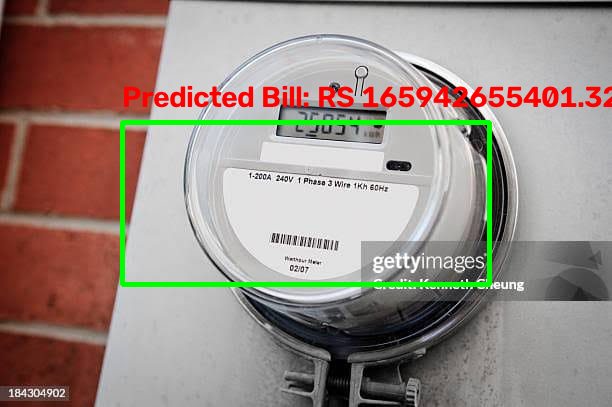

In [ ]:
launch_upload_pipeline()
